# Lab | Intro to Probability

**Objective**

Welcome to this Intro to Probability lab, where we explore decision-making scenarios through the lens of probability and strategic analysis. In the business world, making informed decisions is crucial, especially when faced with uncertainties. This lab focuses on scenarios where probabilistic outcomes play a significant role in shaping strategies and outcomes. Students will engage in exercises that require assessing and choosing optimal paths based on data-driven insights. The goal is to enhance your skills by applying probability concepts to solve real-world problems.

**Challenge 1**

#### Ironhack Airlines 

Often Airlines sell more tickets than they have seats available, this is called overbooking. Consider the following:
- A plane has 450 seats. 
- Based on historical data we conclude that each individual passenger has a 3% chance of missing it's flight. 

If the Ironhack Airlines routinely sells 460 tickets, what is the chance that they have a seats for all passenger?

In [1]:
# Step 0 - Import libraries we need
# import = load external library
# scipy.stats = has probability distributions (binomial, poisson, normal, exponential)
from scipy import stats
import math


In [2]:
# Challenge 1 - Define known values
n = 460          # number of tickets sold
p_miss = 0.03    # probability a passenger misses

# misses ~ Binomial(n, p_miss)
# We want P(misses >= 10)
# sf(k-1) = P(X > k-1) = P(X >= k)
prob_seats_for_all = stats.binom.sf(9, n, p_miss)

prob_seats_for_all


np.float64(0.8844772466215439)

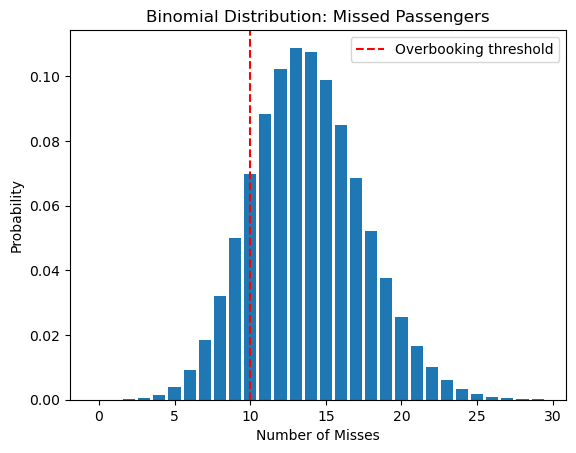

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Range of possible misses
misses = np.arange(0, 30)
pmf = stats.binom.pmf(misses, n, p_miss)

plt.bar(misses, pmf)
plt.axvline(10, color='red', linestyle='--', label='Overbooking threshold')
plt.title("Binomial Distribution: Missed Passengers")
plt.xlabel("Number of Misses")
plt.ylabel("Probability")
plt.legend()
plt.show()


In [4]:
# 📊 Recommended Chart: Binomial PMF

# Why?
# -Shows how likely different numbers of “missed passengers” are
# -Makes it obvious why “≥ 10 misses” is safe
# ✔ Interpretation: Most probability mass is around ~14 misses → selling 460 is safe.

**Challenge 2**

#### Ironhack Call Center 

Suppose a customer service representative at a call center is handling customer complaints. Consider the following:
- The probability of successfully resolving a customer complaint on the first attempt is 0.3. 


What is the probability that the representative needs to make at least three attempts before successfully resolving a customer complaint?

In [5]:
# Challenge 2 - Given probability of success per attempt
p = 0.3

# at least 3 attempts before success = need more than 3 attempts
# first 3 attempts are failures -> (1-p)^3
prob_at_least_three_attempts_before_success = (1 - p) ** 3

prob_at_least_three_attempts_before_success


0.3429999999999999

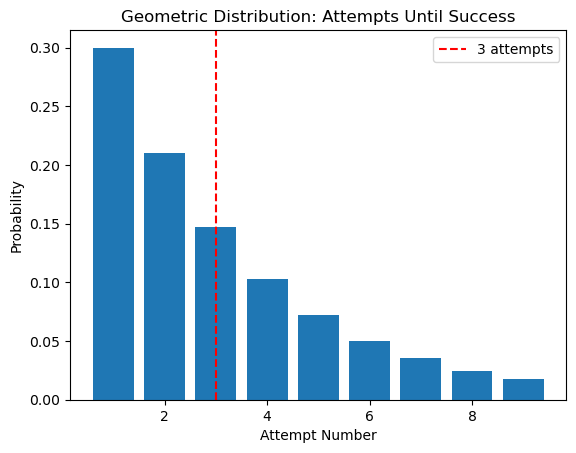

In [6]:
attempts = np.arange(1, 10)
pmf = stats.geom.pmf(attempts, p)

plt.bar(attempts, pmf)
plt.axvline(3, color='red', linestyle='--', label='3 attempts')
plt.title("Geometric Distribution: Attempts Until Success")
plt.xlabel("Attempt Number")
plt.ylabel("Probability")
plt.legend()
plt.show()


In [7]:
#📊 Recommended Chart: Geometric PMF

#Why?
#-Shows how many attempts are usually needed
#-Makes “3 failed attempts first” intuitive
#✔ Interpretation: Probability drops fast → most issues are resolved early.

**Challenge 3**

#### Ironhack Website

Consider a scenario related to Ironhack website traffic. Where:
- our website takes on average 500 visits per hour.
- the website's server is designed to handle up to 550 vists per hour.


What is the probability of the website server being overwhelmed?

In [8]:
# Challenge 3 - Given mean rate per hour
lam = 500  # lambda = average visits per hour

# Visits per hour ~ Poisson(lam)
# P(overwhelmed) = P(X > 550) = sf(550)
prob_overwhelmed_one_hour = stats.poisson.sf(550, lam)

prob_overwhelmed_one_hour


np.float64(0.012898220840392029)

What is the probability of being overwhelmed at some point during a day? (consider 24hours)

In [9]:
# Probability overwhelmed at least once in 24 hours
prob_overwhelmed_anytime_24h = 1 - (1 - prob_overwhelmed_one_hour) ** 24

prob_overwhelmed_anytime_24h


np.float64(0.2677043869515715)

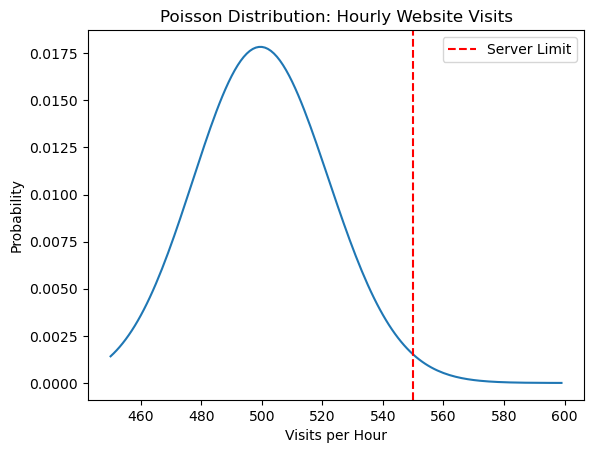

In [10]:
visits = np.arange(450, 600)
pmf = stats.poisson.pmf(visits, lam)

plt.plot(visits, pmf)
plt.axvline(550, color='red', linestyle='--', label='Server Limit')
plt.title("Poisson Distribution: Hourly Website Visits")
plt.xlabel("Visits per Hour")
plt.ylabel("Probability")
plt.legend()
plt.show()


In [11]:
#📊 Recommended Chart: Poisson PMF

#Why?
#-Shows how rare extreme traffic spikes are
#-Makes “>550 visits” visually obvious
#✔ Interpretation: Overload events are tail events → rare but possible.

**Challenge 4**

#### Ironhack Helpdesk

Consider a scenario related to the time between arrivals of customers at a service desk.

On average, a customers arrives every 10minutes.

What is the probability that the next customer will arrive within the next 5 minutes?

In [12]:
# Challenge 4 - Mean time between arrivals (minutes)
mean_minutes = 10

# rate (lambda) = 1/mean
rate = 1 / mean_minutes

# exponential distribution: stats.expon(scale=mean) because scale = 1/rate
# CDF gives P(T <= t)
prob_within_5 = stats.expon.cdf(5, scale=mean_minutes)

prob_within_5


np.float64(0.3934693402873666)

If there is no customer for 15minutes, employees can that a 5minutes break.

What is the probability an employee taking a break?

In [13]:
# P(T > 15) = survival function sf(15)
prob_break = stats.expon.sf(15, scale=mean_minutes)

prob_break


np.float64(0.22313016014842982)

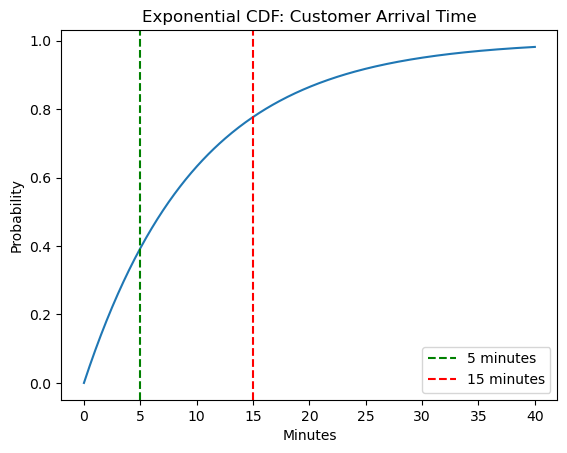

In [14]:
x = np.linspace(0, 40, 400)
cdf = stats.expon.cdf(x, scale=mean_minutes)

plt.plot(x, cdf)
plt.axvline(5, color='green', linestyle='--', label='5 minutes')
plt.axvline(15, color='red', linestyle='--', label='15 minutes')
plt.title("Exponential CDF: Customer Arrival Time")
plt.xlabel("Minutes")
plt.ylabel("Probability")
plt.legend()
plt.show()


In [15]:
#📊 Recommended Chart: Exponential CDF

#Why?
#-Shows waiting-time probabilities
#-Perfect for “within X minutes” questions
#✔ Interpretation:
#-Quick arrivals are common
#-Long waits become increasingly unlikely

**Challenge 5**

The weights of a certain species of birds follow a normal distribution with a mean weight of 150 grams and a standard deviation of 10 grams. 

- If we randomly select a bird, what is the probability that its weight is between 140 and 160 grams?

In [16]:
# Challenge 5 - Normal distribution parameters
mu = 150
sigma = 10

# Use CDF: P(a <= X <= b) = CDF(b) - CDF(a)
prob_140_160 = stats.norm.cdf(160, loc=mu, scale=sigma) - stats.norm.cdf(140, loc=mu, scale=sigma)

prob_140_160


np.float64(0.6826894921370859)

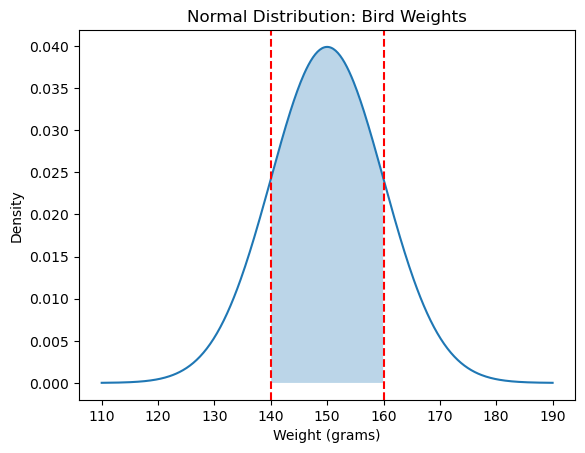

In [17]:
x = np.linspace(110, 190, 400)
pdf = stats.norm.pdf(x, mu, sigma)

plt.plot(x, pdf)
plt.fill_between(x, pdf, where=(x >= 140) & (x <= 160), alpha=0.3)
plt.axvline(140, color='red', linestyle='--')
plt.axvline(160, color='red', linestyle='--')
plt.title("Normal Distribution: Bird Weights")
plt.xlabel("Weight (grams)")
plt.ylabel("Density")
plt.show()


In [18]:
#📊 Recommended Chart: Normal PDF + shaded area

#Why?
#-Classic probability visualization
#-Shows exactly what “between 140 and 160” means
#✔ Interpretation: About ~68% fall within ±1σ (140–160g).

**Challenge 6**

If the lifetime (in hours) of a certain electronic component follows an exponential distribution with a mean lifetime of 50 hours, what is the probability that the component fails within the first 30 hours?

In [19]:
# Challenge 6 - Mean lifetime in hours
mean_life = 50

# P(fails within first 30 hours) = P(T <= 30)
prob_fail_30 = stats.expon.cdf(30, scale=mean_life)

prob_fail_30


np.float64(0.4511883639059735)

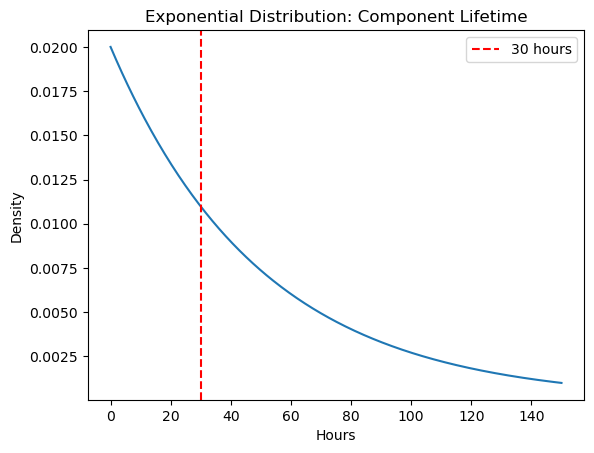

In [20]:
x = np.linspace(0, 150, 400)
pdf = stats.expon.pdf(x, scale=mean_life)

plt.plot(x, pdf)
plt.axvline(30, color='red', linestyle='--', label='30 hours')
plt.title("Exponential Distribution: Component Lifetime")
plt.xlabel("Hours")
plt.ylabel("Density")
plt.legend()
plt.show()


In [21]:
#📊 Recommended Chart: Exponential PDF

#Why?
#-Shows failure risk over time
#-Highlights “early failure probability”
#✔ Interpretation: Highest failure risk is early → classic exponential behavior.

In [22]:
#🔥  Summary Table (What to Use Where)

# Challenge	        Distribution	Best Chart

# Airlines	        Binomial	    PMF bar plot
# Call Center	    Geometric	    PMF bar plot
# Website	        Poisson	        PMF / line plot
# Helpdesk	        Exponential	    CDF
# Bird Weights	    Normal	        PDF + shaded area
# Component Life	Exponential	    PDF